# Projet ML : 4 modèles de prédiction (2 classifications + 2 régressions)

| Dataset | Type | Cible |
|---|---|---|
| Telephone_data.csv | Classification | `etat` |
| Car_Data.csv | Classification | `Venant_Occasion` |
| Car_dataset.csv | Régression | `Selling_Price` |
| taxi_trip_pricing.csv | Régression | `Trip_Price` |

**Dans Colab** : importer les 4 fichiers CSV dans `/content` avant de lancer. À la fin, le dossier `models/` est à télécharger pour l'application Streamlit.

### <font color = 'teal'>Importer les packages<font>

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
warnings.filterwarnings("ignore")
print("scikit-learn :", sklearn.__version__)  # à reporter dans requirements.txt

scikit-learn : 1.8.0


### <font color = 'teal'>Module utils.py (prétraitement réutilisé par l'application)<font>
Le prétraitement est mis **dans le pipeline** : l'application applique ainsi exactement les mêmes transformations aux nouvelles données.

In [2]:
%%writefile utils.py
"""Outils partagés entre le notebook d'entraînement et l'application Streamlit.

IMPORTANT : la classe IQRClipper est sauvegardée DANS les pipelines (.pkl).
Ce fichier doit donc être présent à côté de app.py pour que joblib puisse
recharger les modèles.
"""
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder


class IQRClipper(BaseEstimator, TransformerMixin):
    """Ramène les valeurs aberrantes (méthode IQR) dans les bornes [Q1-1.5*IQR ; Q3+1.5*IQR].

    Les bornes sont apprises UNIQUEMENT sur les données d'entraînement (pas de fuite de données)
    et réutilisées telles quelles sur les nouvelles données.
    """

    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1 = np.nanpercentile(X, 25, axis=0)
        q3 = np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        # IQR nul (colonne quasi constante) : on ne coupe rien
        flat = iqr == 0
        self.lower_[flat] = np.nanmin(X, axis=0)[flat]
        self.upper_[flat] = np.nanmax(X, axis=0)[flat]
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lower_, self.upper_)  # les NaN restent NaN (imputés ensuite)

    def get_feature_names_out(self, input_features=None):
        return input_features


def build_preprocessor(num_cols, cat_cols):
    """Prétraitement complet : outliers -> valeurs manquantes -> normalisation / encodage."""
    num_pipe = Pipeline([
        ("outliers", IQRClipper()),
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", MinMaxScaler()),
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])


Overwriting utils.py


In [3]:
from utils import build_preprocessor

### <font color = 'teal'>Fonctions communes<font>

In [4]:
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             r2_score, mean_squared_error, mean_absolute_error)

os.makedirs("models", exist_ok=True)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def split_data(X, y, stratify=False):
    # train (80%), val (10%), test (10%)
    s = y if stratify else None
    X_tr, X_vt, y_tr, y_vt = train_test_split(X, y, train_size=0.8, random_state=42, stratify=s)
    s = y_vt if stratify else None
    X_val, X_te, y_val, y_te = train_test_split(X_vt, y_vt, train_size=0.5, random_state=42, stratify=s)
    return X_tr, X_val, X_te, y_tr, y_val, y_te

def column_types(X):
    num_cols = X.select_dtypes(include="number").columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    return num_cols, cat_cols

def eval_clf(model, X, y):
    p = model.predict(X)
    return {"Accuracy": accuracy_score(y, p), "F1 (weighted)": f1_score(y, p, average="weighted")}

def eval_reg(model, X, y):
    p = model.predict(X)
    return {"R2": r2_score(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p)}

def run_models(task, df, target, key, title):
    """Entraîne 3 modèles (GridSearch), choisit le meilleur sur la validation, évalue sur le test."""
    X, y = df.drop(columns=target), df[target]
    num_cols, cat_cols = column_types(X)
    X_tr, X_val, X_te, y_tr, y_val, y_te = split_data(X, y, stratify=(task == "classification"))

    if task == "classification":
        candidates = {
            "Logistic Regression": (LogisticRegression(max_iter=3000), {"model__C": [0.1, 1, 10]}),
            "Decision Tree": (DecisionTreeClassifier(random_state=42),
                              {"model__criterion": ["gini", "entropy"], "model__max_depth": [5, 8, 12]}),
            "Random Forest": (RandomForestClassifier(random_state=42, n_jobs=-1),
                              {"model__n_estimators": [50, 100], "model__max_depth": [10, 15],
                               "model__criterion": ["gini", "entropy"]}),
        }
        scoring, evaluate, main_metric = "accuracy", eval_clf, "F1 (weighted)"
    else:
        candidates = {
            "Linear Regression": (LinearRegression(), {}),
            "Decision Tree": (DecisionTreeRegressor(random_state=42),
                              {"model__max_depth": [5, 8, 12], "model__min_samples_leaf": [1, 5]}),
            "Random Forest": (RandomForestRegressor(random_state=42, n_jobs=-1),
                              {"model__n_estimators": [50, 100], "model__max_depth": [10, 15]}),
        }
        scoring, evaluate, main_metric = "r2", eval_reg, "R2"

    fitted, rows = {}, []
    for name, (est, grid) in candidates.items():
        pipe = Pipeline([("prep", build_preprocessor(num_cols, cat_cols)), ("model", est)])
        gs = GridSearchCV(pipe, grid or {"model": [est]}, cv=cv, scoring=scoring, n_jobs=-1)
        gs.fit(X_tr, y_tr)
        fitted[name] = gs.best_estimator_
        rows.append({"Modèle": name, **evaluate(gs.best_estimator_, X_val, y_val),
                     "Meilleurs paramètres": {k.replace("model__", ""): v for k, v in gs.best_params_.items()
                                              if k != "model"}})
    res = pd.DataFrame(rows)
    best_name = res.loc[res[main_metric].idxmax(), "Modèle"]
    best = fitted[best_name]
    test_metrics = evaluate(best, X_te, y_te)

    bundle = {
        "key": key, "title": title, "task": task, "target": target,
        "pipeline": best, "best_name": best_name,
        "num_cols": num_cols, "cat_cols": cat_cols,
        "cat_values": {c: sorted(X[c].dropna().astype(str).unique().tolist()) for c in cat_cols},
        "num_info": {c: {"min": float(X[c].min()), "max": float(X[c].max()), "median": float(X[c].median()),
                         "is_int": bool(pd.api.types.is_integer_dtype(X[c]) or (X[c].dropna() % 1 == 0).all())}
                     for c in num_cols},
        "classes": [str(c) for c in best.classes_] if task == "classification" else None,
        "val_results": res.drop(columns="Meilleurs paramètres").round(4).to_dict("records"),
        "test_metrics": {k: float(v) for k, v in test_metrics.items()},
        "n_rows": int(len(df)), "sklearn_version": sklearn.__version__,
    }
    joblib.dump(bundle, f"models/{key}.pkl", compress=3)
    print(f"Meilleur modèle : {best_name} | test : { {k: round(v, 4) for k, v in test_metrics.items()} }")
    print(f"Sauvegardé -> models/{key}.pkl ({os.path.getsize(f'models/{key}.pkl')/1e6:.1f} Mo)")
    return best, res, (X_val, y_val, X_te, y_te)

def plot_perf(res, metric):
    plt.figure(figsize=(6, 3)); sns.barplot(data=res, x="Modèle", y=metric, hue="Modèle", legend=False)
    plt.title(f"{metric} sur la validation"); plt.show()

def plot_cm(model, X, y):
    ConfusionMatrixDisplay(confusion_matrix(y, model.predict(X), labels=model.classes_),
                           display_labels=model.classes_).plot(cmap="Blues", xticks_rotation=30)
    plt.title("Matrice de confusion (test)"); plt.show()

def plot_reg(model, X, y):
    p = model.predict(X)
    plt.figure(figsize=(4.5, 4.5)); plt.scatter(y, p, alpha=.4)
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]; plt.plot(lim, lim, "r--")
    plt.xlabel("Valeur réelle"); plt.ylabel("Valeur prédite"); plt.title("Réel vs prédit (test)"); plt.show()

## <font color = 'teal'>1) Telephone_data : classification de l'état (`etat`)<font>

In [5]:
df = pd.read_csv('Telephone_data.csv')
print(df.shape); df.head()

(3253, 7)


,prix,adresse,marque,dim_ecr,ram,stockage,etat
0,580000,Guediawaye,iPhone,6.0,8,128,D'occasion
1,250000,Mermoz,iPhone,6.0,4,128,D'occasion
2,80000,Médina,iPhone,5.0,5,128,D'occasion
3,290000,Plateau,Samsung,6.0,8,256,D'occasion
4,250000,Mermoz,Samsung,6.0,8,256,D'occasion


In [6]:
df.info(); print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 3253 entries, 0 to 3252
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   prix      3253 non-null   int64  
 1   adresse   3253 non-null   str    
 2   marque    3253 non-null   str    
 3   dim_ecr   3253 non-null   float64
 4   ram       3253 non-null   int64  
 5   stockage  3253 non-null   int64  
 6   etat      3253 non-null   str    
dtypes: float64(1), int64(3), str(3)
memory usage: 252.6 KB
prix        0
adresse     0
marque      0
dim_ecr     0
ram         0
stockage    0
etat        0
dtype: int64


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
prix,3253.0,360830.307101,215801.003089,1.0,237043.0,362043.0,462044.0,3335000.0
dim_ecr,3253.0,6.510913,3.466092,0.0,6.0,6.0,7.0,75.0
ram,3253.0,16.377498,20.291301,1.0,11.0,12.0,14.0,512.0
stockage,3253.0,193.514294,169.625904,1.0,128.0,158.0,256.0,5120.0


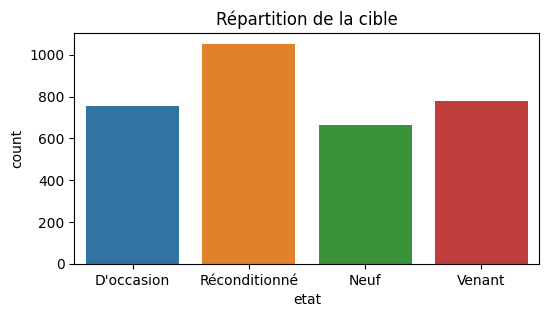

In [8]:
plt.figure(figsize=(6,3)); sns.countplot(data=df, x='etat', hue='etat', legend=False)
plt.title("Répartition de la cible"); plt.show()

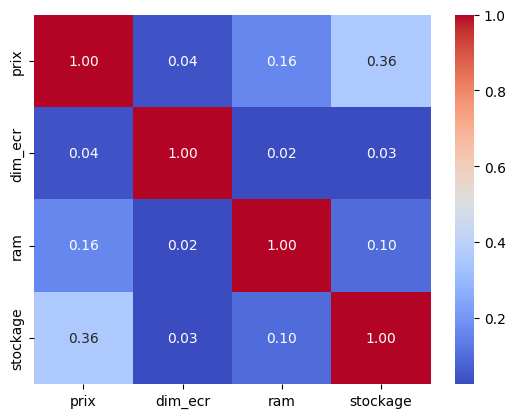

In [9]:
quant = df.select_dtypes(include='number')
sns.heatmap(quant.corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.show()

###### <font color = 'bisque'> Préparation : les outliers (dim_ecr, ram, stockage...) sont gérés dans le pipeline (IQR), l'encodage et la normalisation aussi.

In [10]:
model_tel, res_tel, (Xv, yv, Xt, yt) = run_models("classification", df, "etat", "telephone", "Téléphones : état")
res_tel

Meilleur modèle : Random Forest | test : {'Accuracy': 0.8466, 'F1 (weighted)': 0.8464}
Sauvegardé -> models/telephone.pkl (0.8 Mo)


,Modèle,Accuracy,F1 (weighted),Meilleurs paramètres
0,Logistic Regression,0.846154,0.846465,{'C': 1}
1,Decision Tree,0.818462,0.816035,"{'criterion': 'gini', 'max_depth': 12}"
2,Random Forest,0.873846,0.873264,"{'criterion': 'gini', 'max_depth': 15, 'n_esti..."


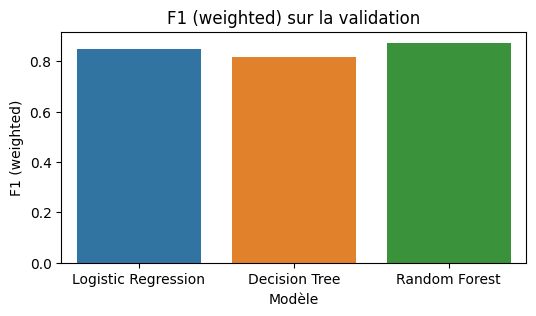

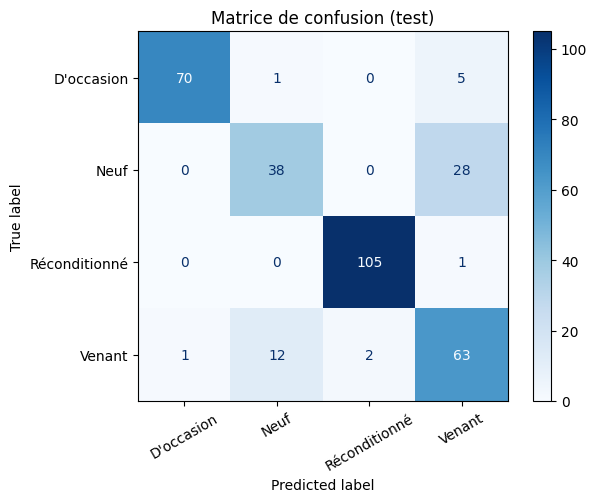

In [11]:
plot_perf(res_tel, "F1 (weighted)"); plot_cm(model_tel, Xt, yt)

## <font color = 'teal'>2) Car_Data : classification Venant / D'occasion (`Venant_Occasion`)<font>

In [12]:
df = pd.read_csv('Car_Data.csv')
print(df.shape); df.head()

(5507, 6)


,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant


In [13]:
df.info(); print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Marque           5507 non-null   str  
 1   Année            5507 non-null   int64
 2   Boite_Vitesse    5507 non-null   str  
 3   Adresse          5507 non-null   str  
 4   Prix             5507 non-null   int64
 5   Venant_Occasion  5507 non-null   str  
dtypes: int64(2), str(4)
memory usage: 475.3 KB
Marque             0
Année              0
Boite_Vitesse      0
Adresse            0
Prix               0
Venant_Occasion    0
dtype: int64


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Année,5507.0,2.014508e+03,3.089839e+00,1990.0,2013.0,2015.0,2016.0,2024.0
Prix,5507.0,1.110512e+07,1.619639e+07,1.0,4600000.0,7800000.0,12500000.0,779414131.0


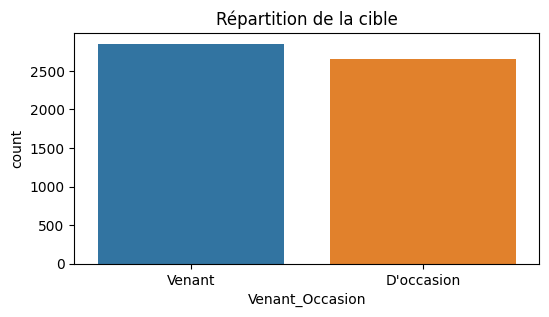

In [15]:
plt.figure(figsize=(6,3)); sns.countplot(data=df, x='Venant_Occasion', hue='Venant_Occasion', legend=False)
plt.title("Répartition de la cible"); plt.show()

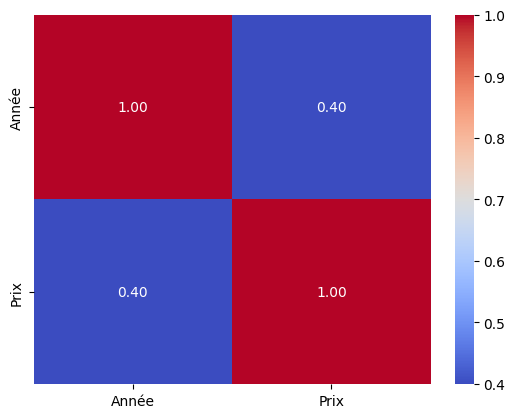

In [16]:
quant = df.select_dtypes(include='number')
sns.heatmap(quant.corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.show()

In [17]:
model_car, res_car, (Xv, yv, Xt, yt) = run_models("classification", df, "Venant_Occasion", "voiture_etat", "Voitures : Venant ou D'occasion")
res_car

Meilleur modèle : Random Forest | test : {'Accuracy': 0.8221, 'F1 (weighted)': 0.8217}
Sauvegardé -> models/voiture_etat.pkl (0.4 Mo)


,Modèle,Accuracy,F1 (weighted),Meilleurs paramètres
0,Logistic Regression,0.765880,0.765462,{'C': 1}
1,Decision Tree,0.791289,0.788170,"{'criterion': 'entropy', 'max_depth': 5}"
2,Random Forest,0.800363,0.797989,"{'criterion': 'entropy', 'max_depth': 15, 'n_e..."


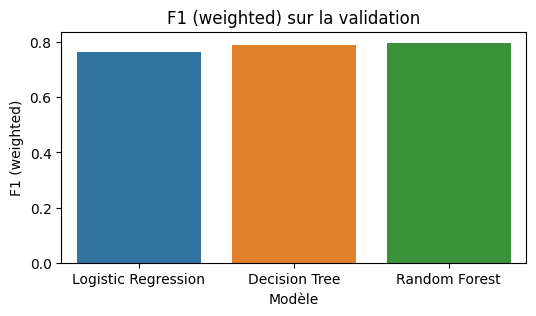

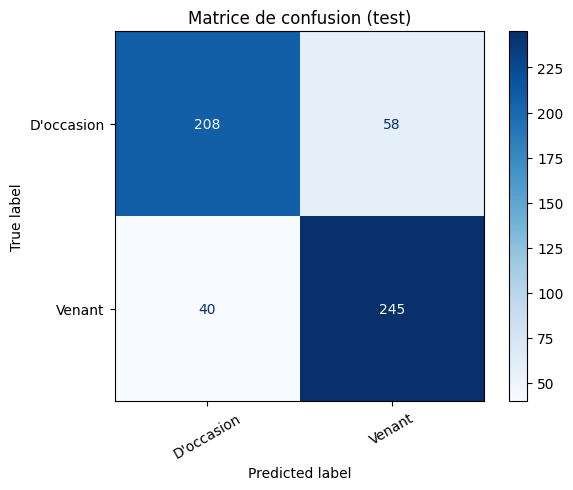

In [18]:
plot_perf(res_car, "F1 (weighted)"); plot_cm(model_car, Xt, yt)

## <font color = 'teal'>3) Car_dataset : régression du prix de vente (`Selling_Price`)<font>

In [19]:
df = pd.read_csv('Car_dataset.csv')
print(df.shape); df.head()

(5861, 7)


,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,Petrol,Dealer,Manual,6,3.35
1,43000,9.54,Diesel,Dealer,Manual,7,4.75
2,6900,9.85,Petrol,Dealer,Manual,3,7.25
3,5200,4.15,Petrol,Dealer,Manual,9,2.85
4,42450,6.87,Diesel,Dealer,Manual,6,4.60


In [20]:
df.info(); print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5861 entries, 0 to 5860
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Kms_Driven     5861 non-null   int64  
 1   Present_Price  5861 non-null   float64
 2   Fuel_Type      5861 non-null   str    
 3   Seller_Type    5861 non-null   str    
 4   Transmission   5861 non-null   str    
 5   Age            5861 non-null   int64  
 6   Selling_Price  5861 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 437.8 KB
Kms_Driven       0
Present_Price    0
Fuel_Type        0
Seller_Type      0
Transmission     0
Age              0
Selling_Price    0
dtype: int64


In [21]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Kms_Driven,5861.0,75209.206108,39198.500980,500.00,53822.000000,71822.000000,87820.000000,538824.000000
Present_Price,5861.0,16.869948,9.659501,0.32,10.552438,15.375776,19.229938,102.661886
Age,5861.0,8.562532,3.099993,2.00,6.000000,8.000000,10.000000,22.000000
Selling_Price,5861.0,10.196217,5.874282,0.10,6.401756,9.049277,11.873727,41.903189


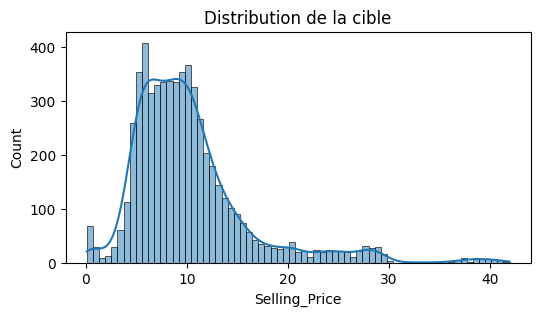

In [22]:
plt.figure(figsize=(6,3)); sns.histplot(df['Selling_Price'].dropna(), kde=True)
plt.title("Distribution de la cible"); plt.show()

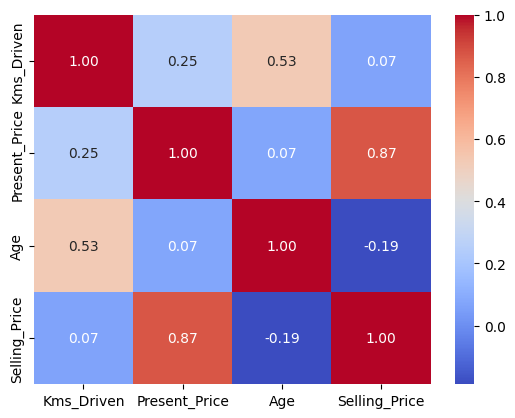

In [23]:
quant = df.select_dtypes(include='number')
sns.heatmap(quant.corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.show()

In [24]:
model_cd, res_cd, (Xv, yv, Xt, yt) = run_models("regression", df, "Selling_Price", "voiture_prix", "Voitures : prix de vente")
res_cd

Meilleur modèle : Random Forest | test : {'R2': 0.9499, 'RMSE': np.float64(1.3653), 'MAE': 0.9425}
Sauvegardé -> models/voiture_prix.pkl (7.2 Mo)


,Modèle,R2,RMSE,MAE,Meilleurs paramètres
0,Linear Regression,0.723742,2.875420,1.801730,{}
1,Decision Tree,0.930622,1.440966,1.089716,"{'max_depth': 12, 'min_samples_leaf': 5}"
2,Random Forest,0.944105,1.293389,0.984939,"{'max_depth': 15, 'n_estimators': 100}"


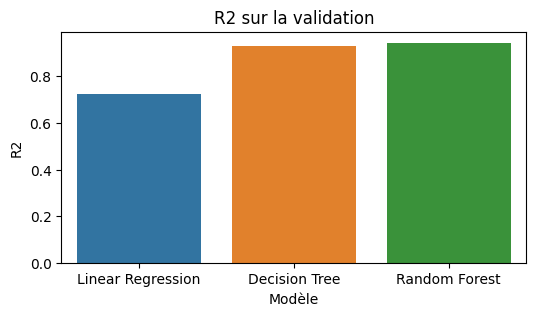

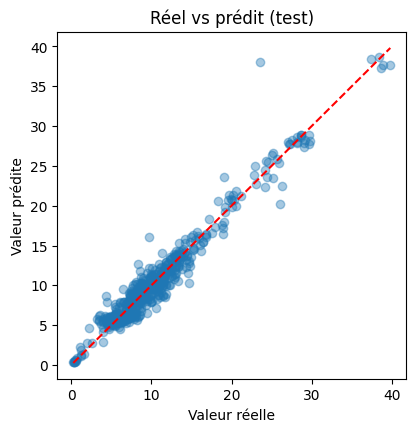

In [25]:
plot_perf(res_cd, "R2"); plot_reg(model_cd, Xt, yt)

## <font color = 'teal'>4) taxi_trip_pricing : régression du prix de la course (`Trip_Price`)<font>
Ce dataset contient des valeurs manquantes (~5 % par colonne) : on supprime les lignes sans cible, les autres valeurs manquantes sont imputées dans le pipeline.

In [26]:
df = pd.read_csv('taxi_trip_pricing.csv')
print(df.shape); df.head()

(1000, 11)


,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.80,0.32,53.82,36.2624
1,47.59,Afternoon,Weekday,1.0,High,Clear,NaN,0.62,0.43,40.57,NaN
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032
3,30.33,Evening,Weekday,4.0,Low,NaN,3.48,0.51,0.15,116.81,36.4698
4,NaN,Evening,Weekday,3.0,High,Clear,2.93,0.63,0.32,22.64,15.6180


In [27]:
df.info(); print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Trip_Distance_km       950 non-null    float64
 1   Time_of_Day            950 non-null    str    
 2   Day_of_Week            950 non-null    str    
 3   Passenger_Count        950 non-null    float64
 4   Traffic_Conditions     950 non-null    str    
 5   Weather                950 non-null    str    
 6   Base_Fare              950 non-null    float64
 7   Per_Km_Rate            950 non-null    float64
 8   Per_Minute_Rate        950 non-null    float64
 9   Trip_Duration_Minutes  950 non-null    float64
 10  Trip_Price             951 non-null    float64
dtypes: float64(7), str(4)
memory usage: 108.5 KB
Trip_Distance_km         50
Time_of_Day              50
Day_of_Week              50
Passenger_Count          50
Traffic_Conditions       50
Weather                  50
Base_Fare  

In [28]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Trip_Distance_km,950.0,27.070547,19.905300,1.2300,12.63250,25.8300,38.40500,146.067047
Passenger_Count,950.0,2.476842,1.102249,1.0000,1.25000,2.0000,3.00000,4.000000
Base_Fare,950.0,3.502989,0.870162,2.0100,2.73000,3.5200,4.26000,5.000000
Per_Km_Rate,950.0,1.233316,0.429816,0.5000,0.86000,1.2200,1.61000,2.000000
Per_Minute_Rate,950.0,0.292916,0.115592,0.1000,0.19000,0.2900,0.39000,0.500000
Trip_Duration_Minutes,950.0,62.118116,32.154406,5.0100,35.88250,61.8600,89.05500,119.840000
Trip_Price,951.0,56.874773,40.469791,6.1269,33.74265,50.0745,69.09935,332.043689


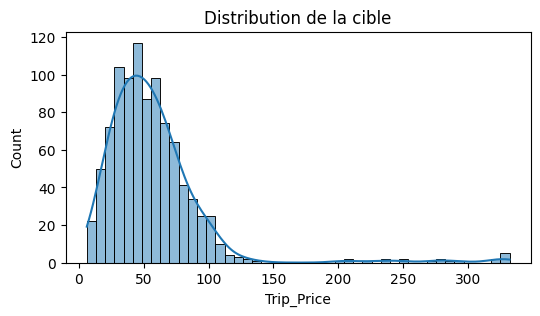

In [29]:
plt.figure(figsize=(6,3)); sns.histplot(df['Trip_Price'].dropna(), kde=True)
plt.title("Distribution de la cible"); plt.show()

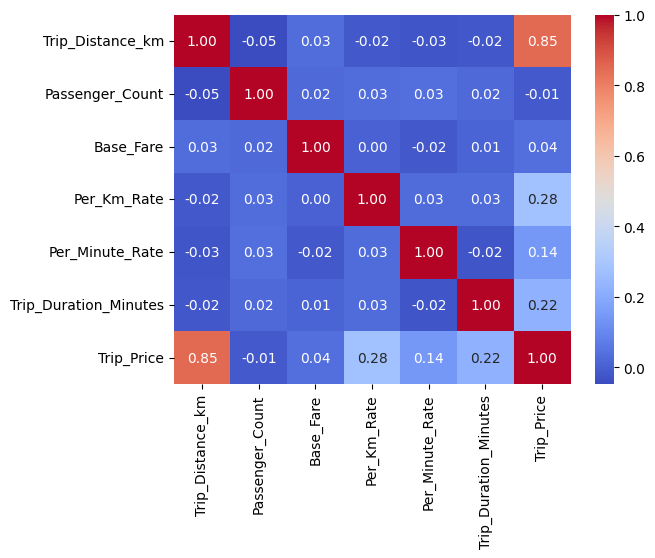

In [30]:
quant = df.select_dtypes(include='number')
sns.heatmap(quant.corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.show()

In [31]:
df = df.dropna(subset=['Trip_Price']).reset_index(drop=True)
model_tx, res_tx, (Xv, yv, Xt, yt) = run_models("regression", df, "Trip_Price", "taxi_prix", "Taxi : prix de la course")
res_tx

Meilleur modèle : Random Forest | test : {'R2': 0.9584, 'RMSE': np.float64(8.8638), 'MAE': 5.3163}
Sauvegardé -> models/taxi_prix.pkl (1.8 Mo)


,Modèle,R2,RMSE,MAE,Meilleurs paramètres
0,Linear Regression,0.605400,33.170123,14.839287,{}
1,Decision Tree,0.867141,19.247045,10.721102,"{'max_depth': 8, 'min_samples_leaf': 5}"
2,Random Forest,0.929085,14.061690,7.262842,"{'max_depth': 15, 'n_estimators': 100}"


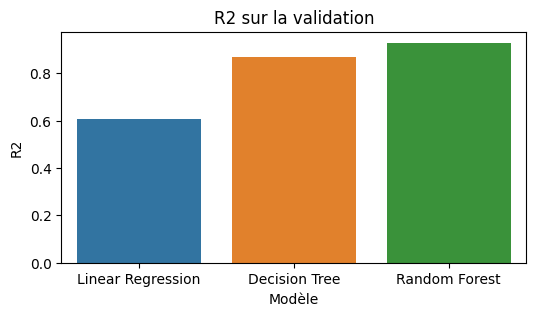

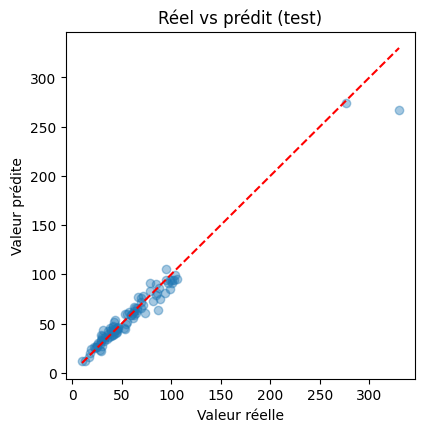

In [32]:
plot_perf(res_tx, "R2"); plot_reg(model_tx, Xt, yt)

## <font color = 'teal'>Récapitulatif et export<font>

In [33]:
rec = []
for f in sorted(os.listdir("models")):
    b = joblib.load(f"models/{f}")
    rec.append({"Fichier": f, "Titre": b["title"], "Type": b["task"], "Meilleur modèle": b["best_name"], **b["test_metrics"]})
pd.DataFrame(rec).round(4)

,Fichier,Titre,Type,Meilleur modèle,R2,RMSE,MAE,Accuracy,F1 (weighted)
0,taxi_prix.pkl,Taxi : prix de la course,regression,Random Forest,0.9584,8.8638,5.3163,NaN,NaN
1,telephone.pkl,Téléphones : état,classification,Random Forest,NaN,NaN,NaN,0.8466,0.8464
2,voiture_etat.pkl,Voitures : Venant ou D'occasion,classification,Random Forest,NaN,NaN,NaN,0.8221,0.8217
3,voiture_prix.pkl,Voitures : prix de vente,regression,Random Forest,0.9499,1.3653,0.9425,NaN,NaN


In [34]:
# Dans Colab : télécharger le dossier models/ + utils.py
# !zip -r models.zip models utils.py
# from google.colab import files; files.download('models.zip')